# Vehicle Detection - YOLO26n (versi perbaikan)

In [6]:
!pip install -q ultralytics supervision

## 1. Import & konfigurasi

In [7]:
import os, shutil, random
from pathlib import Path

import yaml
import pandas as pd
import supervision as sv
from IPython.display import Image
from ultralytics import YOLO, settings

# Matikan integrasi yang memunculkan warning (ray / wandb)
os.environ['WANDB_MODE'] = 'disabled'
try:
    settings.update({'raytune': False})
except Exception:
    pass

HOME = Path('/kaggle/working')
SRC_DATASET = Path('/kaggle/input/datasets/stevenlee131/vehicle-detection-dataset')
dataset_location = HOME / 'dataset'      # salinan yang bisa ditulis
DATA_YAML = dataset_location / 'data_fixed.yaml'

## 2. Salin dataset ke `/kaggle/working`
`/kaggle/input` bersifat read-only, jadi cache label tidak bisa disimpan (muncul warning *not writable*) dan loading jadi lebih lambat.

In [8]:
# 1. Cek isi dataset asli dulu
print("Dataset asli:", os.listdir(SRC_DATASET))

# 2. Hapus salinan lama yang tidak lengkap, lalu salin ulang
shutil.rmtree(dataset_location, ignore_errors=True)
shutil.copytree(SRC_DATASET, dataset_location)
print("Hasil salinan:", os.listdir(dataset_location))

# 3. Deteksi nama folder otomatis
def find_split(*candidates):
    for c in candidates:
        if (dataset_location / c / 'images').exists():
            return f'{c}/images'
    raise FileNotFoundError(f'Tidak ada folder {candidates} di {os.listdir(dataset_location)}')

with open(dataset_location / 'data.yaml') as f:
    cfg = yaml.safe_load(f)

cfg['path']  = str(dataset_location)
cfg['train'] = find_split('train')
cfg['val']   = find_split('valid', 'val', 'validation')
cfg['test']  = find_split('test')

with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(cfg, f)

print('Kelas:', cfg['names'])
print('train:', cfg['train'], '| val:', cfg['val'], '| test:', cfg['test'])

Dataset asli: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']
Hasil salinan: ['data.yaml', 'train', 'test', 'valid', 'README.roboflow.txt', 'README.dataset.txt']
Kelas: ['bus', 'car', 'van']
train: train/images | val: valid/images | test: test/images


## 3. Training
Perubahan dari versi lama:
- `epochs=50`, `patience=10` (sebelumnya 15 / 5, terlalu singkat)
- `flipud=0.0` (kendaraan tidak pernah terbalik vertikal di dunia nyata), `fliplr=0.5` untuk flip horizontal
- `project` dan `name` ditentukan, jadi lokasi hasil selalu `/kaggle/working/runs/vehicle`

In [9]:
model = YOLO('yolo26s.pt')

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    patience=10,
    batch=16,
    imgsz=800,
    project=str(HOME / 'runs'),
    name='vehicle',
    exist_ok=True,
    save_period=5,
    val=True,
    verbose=True,
    flipud=0.0,
    fliplr=0.0,
    workers=4,
)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle, nbs=64, nms=None, opset=None, optimize=Fa

## 4. Cek hasil training & epoch terbaik

In [19]:
RUN_DIR = HOME / 'runs' / 'vehicle'
BEST = RUN_DIR / 'weights' / 'best.pt'
print(os.listdir(RUN_DIR))
print(os.listdir(RUN_DIR / 'weights'))

df = pd.read_csv(RUN_DIR / 'results.csv')
df.columns = df.columns.str.strip()
best = df.loc[df['metrics/mAP50-95(B)'].idxmax()]
print(f"Epoch terbaik : {int(best['epoch'])}")
print(f"mAP50         : {best['metrics/mAP50(B)']:.4f}")
print(f"mAP50-95      : {best['metrics/mAP50-95(B)']:.4f}")

['train_batch0.jpg', 'val_batch0_pred.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'confusion_matrix_normalized.png', 'BoxP_curve.png', 'weights', 'val_batch1_pred.jpg', 'results.png', 'args.yaml', 'results.csv', 'train_batch1.jpg', 'val_batch1_labels.jpg', 'labels.jpg', 'val_batch0_labels.jpg', 'train_batch2.jpg', 'BoxF1_curve.png', 'confusion_matrix.png', 'val_batch2_pred.jpg', 'BoxPR_curve.png']
['last.pt', 'epoch20.pt', 'epoch25.pt', 'epoch15.pt', 'epoch10.pt', 'best.pt', 'epoch5.pt', 'epoch30.pt', 'epoch0.pt']
Epoch terbaik : 24
mAP50         : 0.8888
mAP50-95      : 0.6917


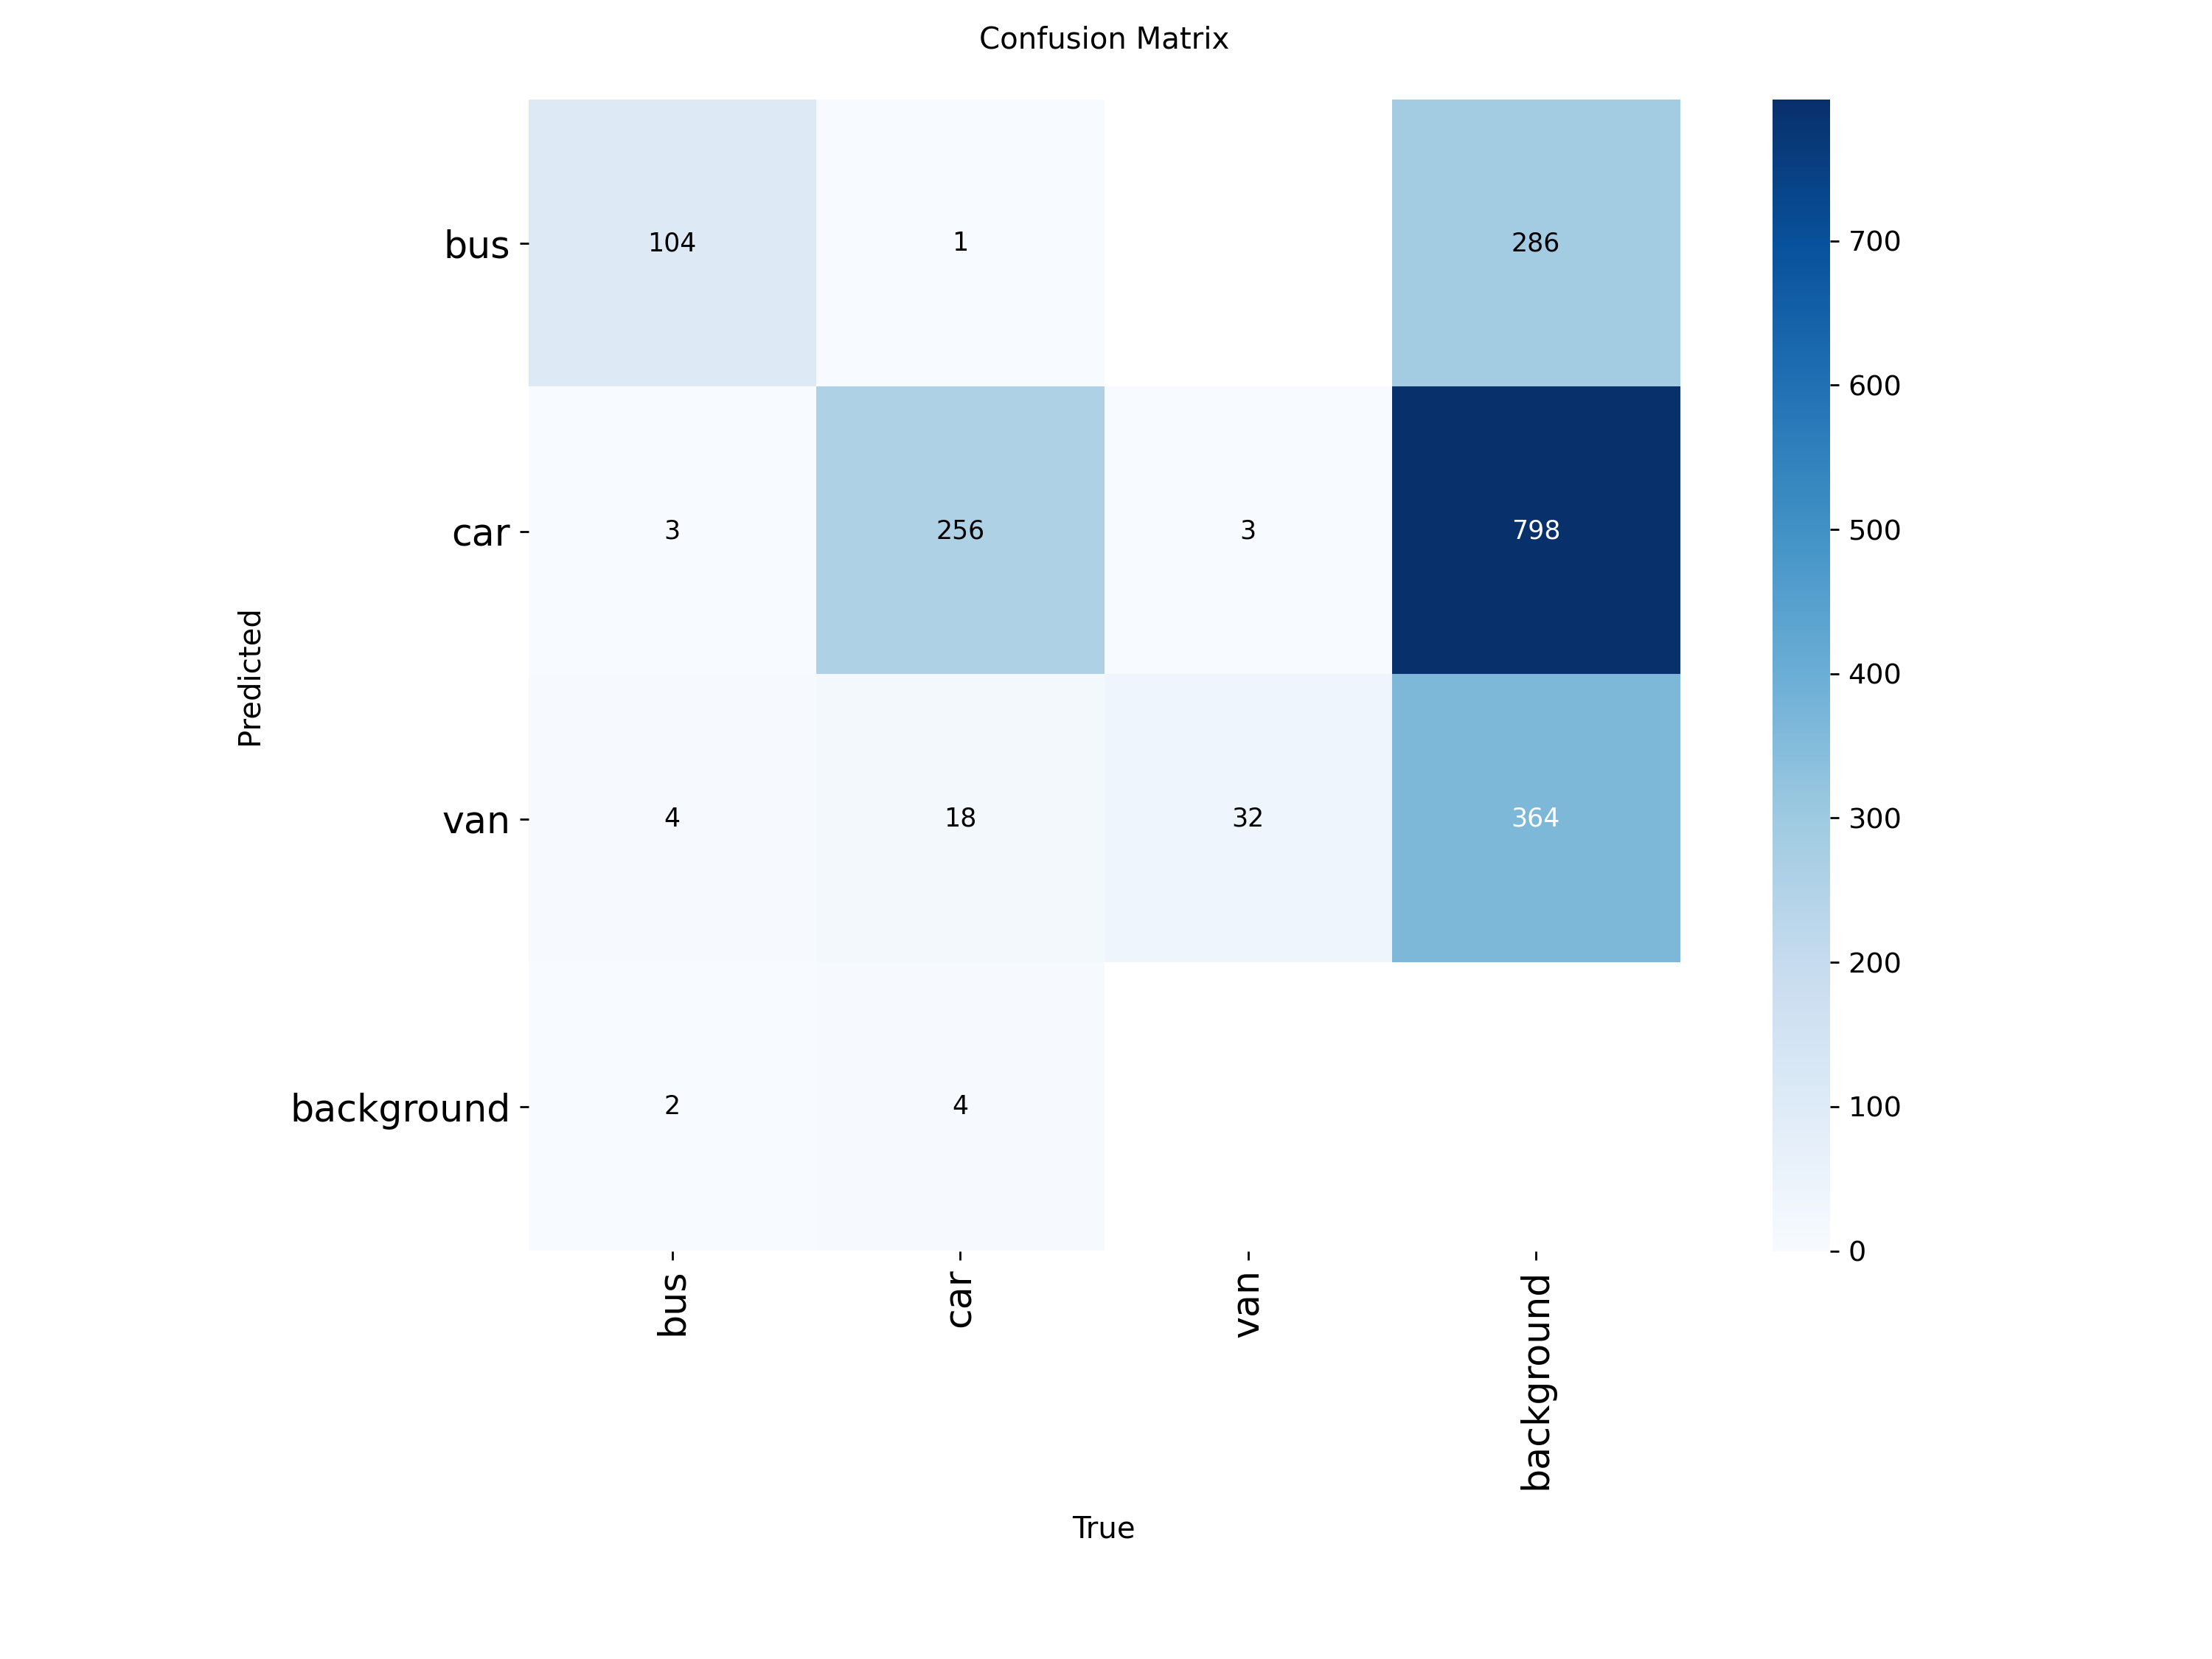

In [20]:
Image(filename=str(RUN_DIR / 'confusion_matrix.png'), width=1000)

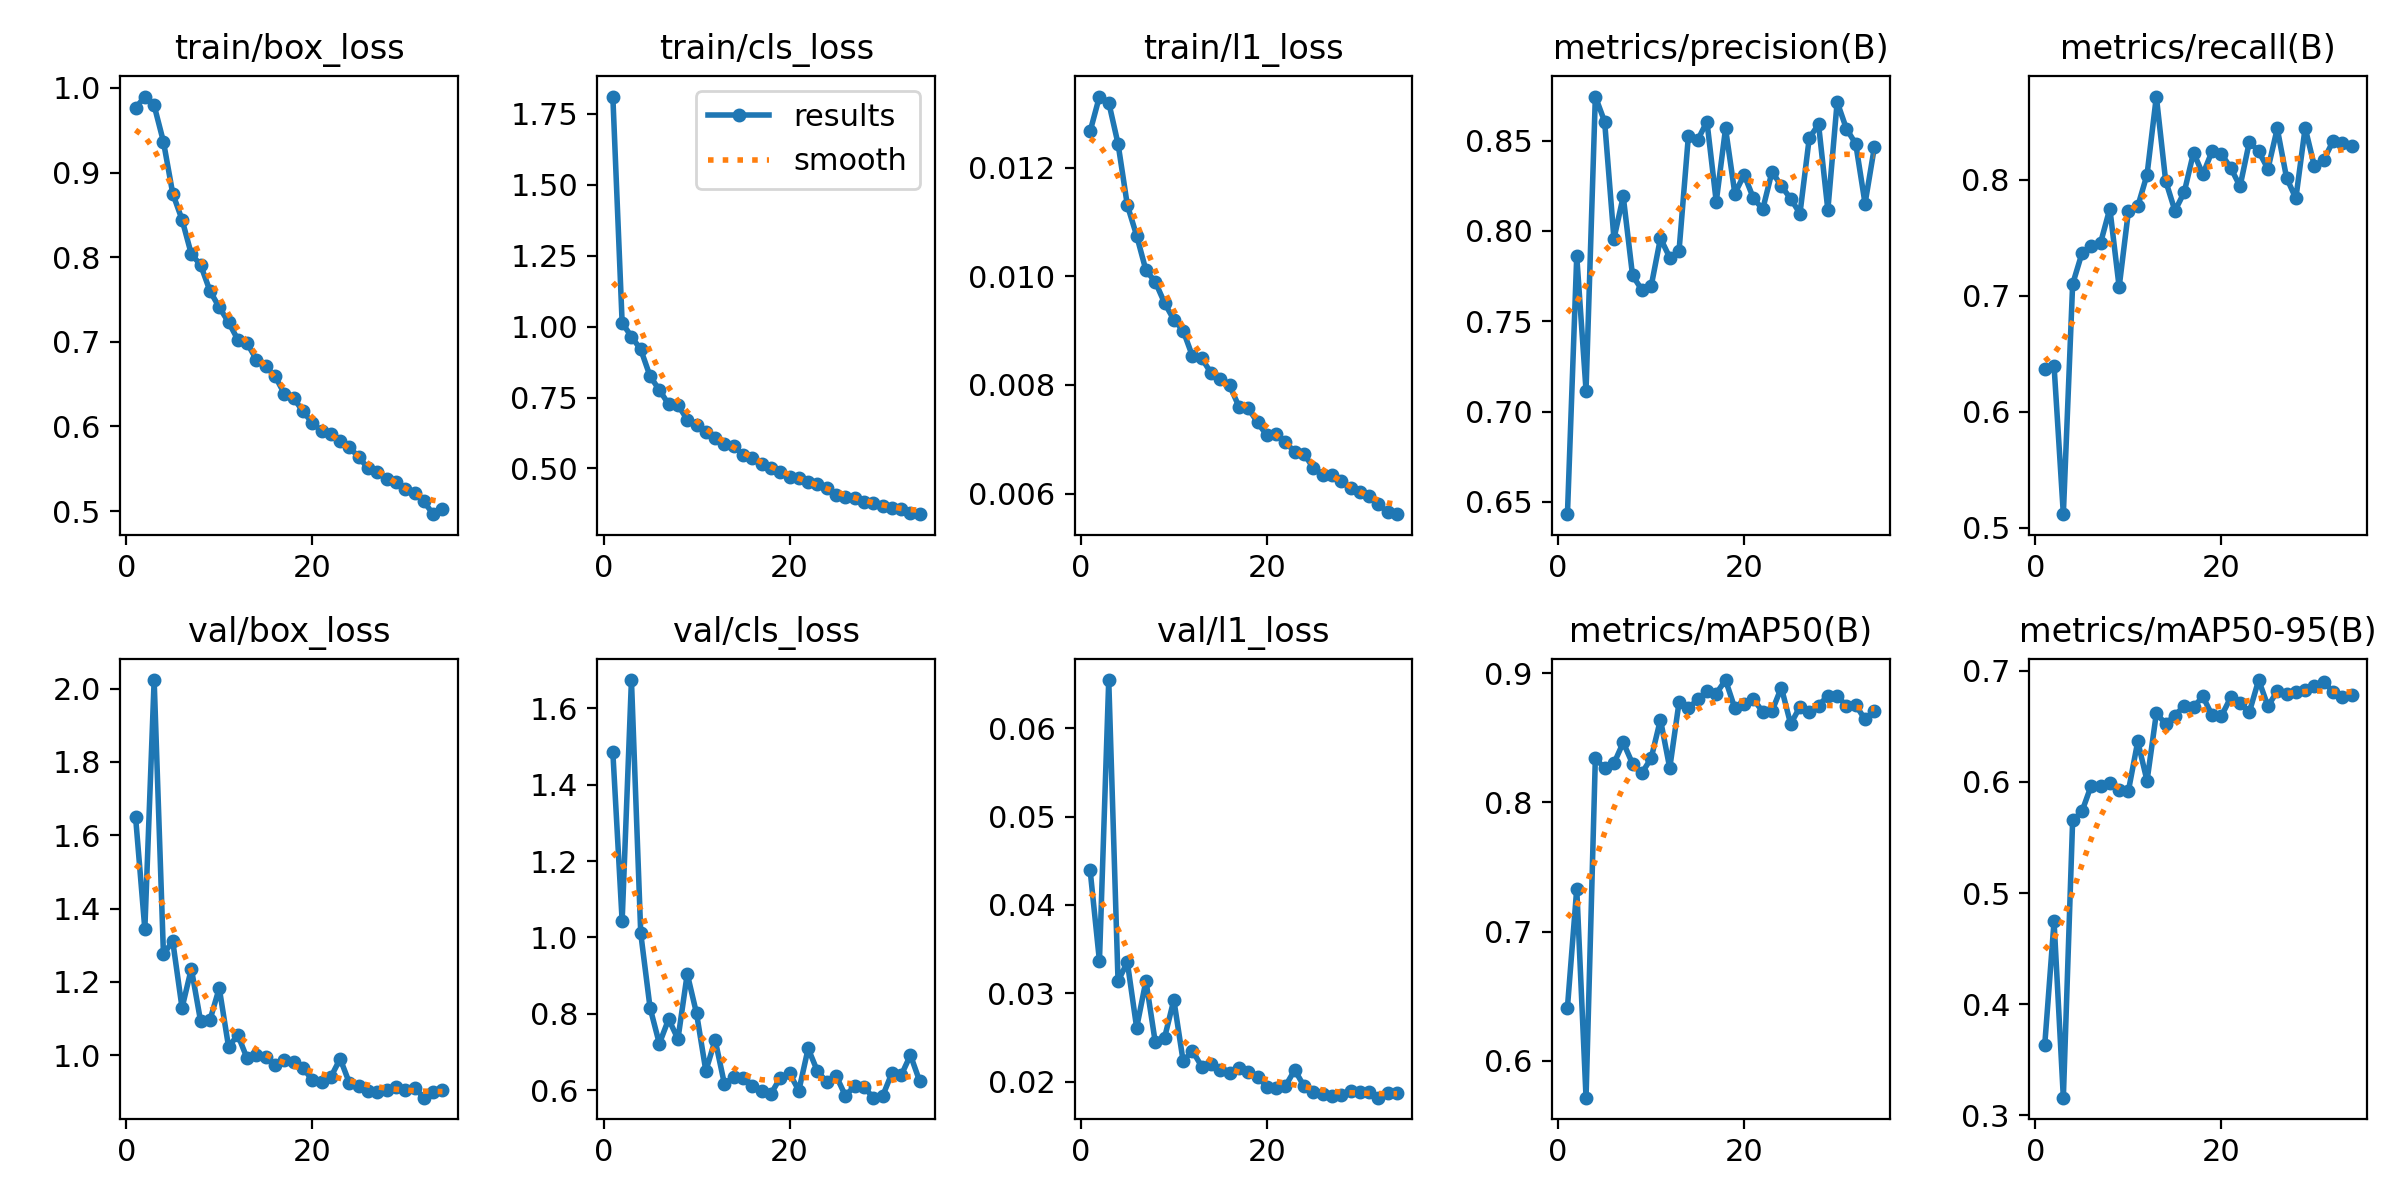

In [21]:
Image(filename=str(RUN_DIR / 'results.png'), width=1000)

## 5. Evaluasi final di data **test**
Angka di data valid dipakai untuk memilih `best.pt`, jadi cenderung optimistis. Laporkan angka dari data test.

In [22]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='test')

print('mAP50-95:', metrics.box.map)
print('mAP50   :', metrics.box.map50)
print('mAP75   :', metrics.box.map75)
for i, name in best_model.names.items():
    print(f'{name:>8} | mAP50-95: {metrics.box.maps[i]:.3f}')

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 991.1±764.3 MB/s, size: 50.4 KB)
val: Scanning /kaggle/working/dataset/test/labels.cache... 220 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 220/220 38.4Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 14, len(boxes) = 413. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.8it/s 5.0s0.4s
                   all        220        413      0.868       0.86       0.92      0.719
                   bus         67        109      0.914      0.872      0.946      0.699
                   car        1

## 6. (Opsional) mAP dengan supervision
Perbaikan: prediksi memakai `conf=0.001`. Dengan threshold default (0.25) banyak deteksi berskor rendah terbuang, sehingga mAP terlihat lebih kecil dari seharusnya.

In [23]:
from supervision.metrics import MeanAveragePrecision

ds = sv.DetectionDataset.from_yolo(
    images_directory_path=str(dataset_location / 'test/images'),
    annotations_directory_path=str(dataset_location / 'test/labels'),
    data_yaml_path=str(DATA_YAML),
)

predictions, targets = [], []
for _, image, target in ds:
    result = best_model(image, conf=0.001, verbose=False)[0]
    predictions.append(sv.Detections.from_ultralytics(result))
    targets.append(target)

map_result = MeanAveragePrecision().update(predictions, targets).compute()
print('mAP 50:95', map_result.map50_95)
print('mAP 50   ', map_result.map50)
print('mAP 75   ', map_result.map75)

mAP 50:95 0.6903617621058286
mAP 50    0.8878746547124566
mAP 75    0.769613937871291


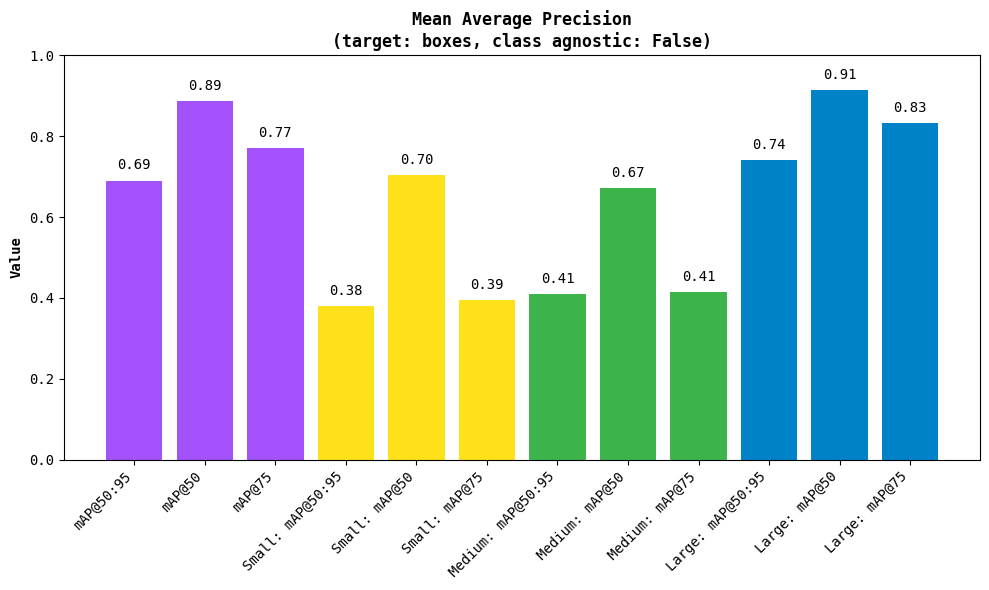

In [24]:
map_result.plot()

## 7. Visualisasi prediksi pada gambar test acak

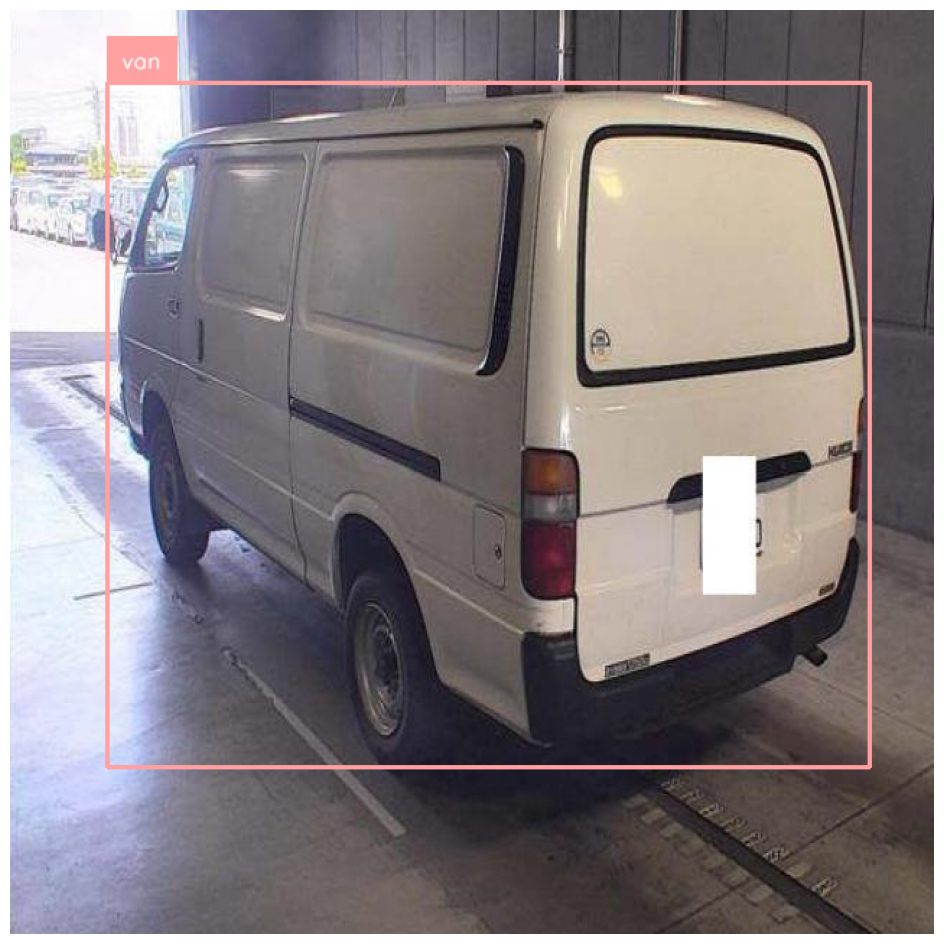

In [28]:
i = random.randint(0, len(ds) - 1)   # sebelumnya len(ds), bisa out-of-range
image_path, image, target = ds[i]

result = best_model(image, verbose=False)[0]
detections = sv.Detections.from_ultralytics(result).with_nms()

annotated = image.copy()
annotated = sv.BoxAnnotator().annotate(scene=annotated, detections=detections)
annotated = sv.LabelAnnotator().annotate(scene=annotated, detections=detections)
sv.plot_image(annotated)

## 8. Ekspor model untuk Streamlit
Hasilnya `best_vehicle.pt` muncul di tab **Output** Kaggle. Download, lalu taruh di folder `models/` project Streamlit.

In [17]:
shutil.copy(BEST, HOME / 'best_vehicle.pt')
print('Tersimpan:', HOME / 'best_vehicle.pt')

Tersimpan: /kaggle/working/best_vehicle.pt


In [18]:
!ls -la /kaggle/working
!find /kaggle -name "best.pt" 2>/dev/null

total 39836
drwxr-xr-x 5 root root     4096 Nov  9 12:16 .
drwxr-xr-x 5 root root     4096 Nov  9 09:45 ..
-rw-r--r-- 1 root root 20342981 Nov  9 12:16 best_vehicle.pt
drwxrwxrwx 5 root root     4096 Nov  9 10:03 dataset
drwxr-xr-x 4 root root     4096 Nov  9 12:16 runs
drwxr-xr-x 2 root root     4096 Nov  9 09:45 .virtual_documents
-rw-r--r-- 1 root root 20422725 Nov  9 09:50 yolo26s.pt
/kaggle/working/runs/vehicle/weights/best.pt
